# Sales Prediction Dataset — Case Project Analysis

## Setup and Cleaning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_excel("advertising_sales_data.xlsx")
df = df.drop(columns=["Campaign"])
df["Radio"] = df["Radio"].fillna(df["Radio"].mean())  # 2 missing values
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.260606,30.554000,15.130500
std,85.854236,14.846740,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.880303,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


## Q1) Average TV advertising spend

In [2]:
avg_tv = df["TV"].mean()
print(f"Average TV spend = {avg_tv:.2f}")

Average TV spend = 147.04


## Q2) Correlation between Radio advertising and Sales

In [3]:
corr_radio_sales = df["Radio"].corr(df["Sales"])
print(f"Correlation(Radio, Sales) = {corr_radio_sales:.4f}")

Correlation(Radio, Sales) = 0.3497


**Answer:** Moderate positive correlation (r ≈ 0.35).

## Q3) Which advertising medium has the highest impact on sales?

In [4]:
df.corr()["Sales"].drop("Sales").sort_values(ascending=False)

TV           0.901208
Radio        0.349651
Newspaper    0.157960
Name: Sales, dtype: float64

**Answer:** TV has by far the strongest correlation with sales (0.90), vs Radio (0.35) and Newspaper (0.16).

## Q4) Linear regression on all variables — predicted vs actual sales

In [5]:
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]
lr_full = LinearRegression().fit(X, y)
y_pred_full = lr_full.predict(X)
r2_full = r2_score(y, y_pred_full)
print(f"R^2 = {r2_full:.4f}")
print(dict(zip(X.columns, lr_full.coef_)))

R^2 = 0.9026
{'TV': np.float64(0.05444596720512242), 'Radio': np.float64(0.10701801458336857), 'Newspaper': np.float64(0.0003225299010955586)}


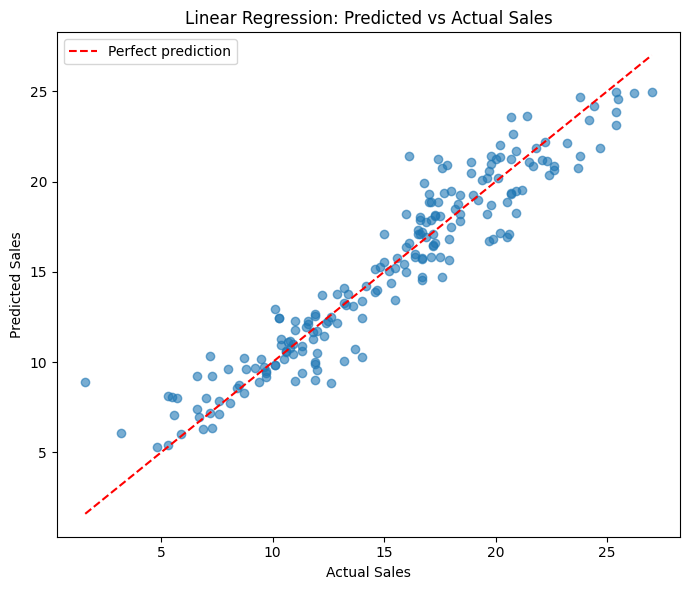

In [6]:
plt.figure(figsize=(7, 6))
plt.scatter(y, y_pred_full, alpha=0.6, color="#1F77B4")
lims = [min(y.min(), y_pred_full.min()), max(y.max(), y_pred_full.max())]
plt.plot(lims, lims, color="red", linestyle="--", label="Perfect prediction")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Linear Regression: Predicted vs Actual Sales")
plt.legend()
plt.tight_layout()
plt.show()

**Answer:** The full model achieves R² = 0.903 — predictions cluster tightly around the diagonal.

## Q5) Predict sales for TV=$200, Radio=$40, Newspaper=$50

In [7]:
new_point = pd.DataFrame([[200, 40, 50]], columns=["TV", "Radio", "Newspaper"])
pred_new = lr_full.predict(new_point)[0]
print(f"Predicted sales = {pred_new:.2f} units")

Predicted sales = 19.81 units


## Q6) Effect of normalization on model performance

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
lr_scaled = LinearRegression().fit(X_scaled, y)
y_pred_scaled = lr_scaled.predict(X_scaled)
r2_scaled = r2_score(y, y_pred_scaled)

print(f"R^2 unnormalized = {r2_full:.4f}")
print(f"R^2 normalized   = {r2_scaled:.4f}")
print("Standardized coefficients (relative importance):")
print(dict(zip(X.columns, lr_scaled.coef_)))

R^2 unnormalized = 0.9026
R^2 normalized   = 0.9026
Standardized coefficients (relative importance):
{'TV': np.float64(4.662716248298932), 'Radio': np.float64(1.584891501046624), 'Newspaper': np.float64(0.007006673778132536)}


**Answer:** Normalizing doesn't change R² — linear regression fit quality is scale-invariant. Standardized coefficients show TV (4.66) matters far more than Radio (1.58) or Newspaper (0.007).

## Q7) Model using only Radio and Newspaper as predictors

In [9]:
X_rn = df[["Radio", "Newspaper"]]
lr_rn = LinearRegression().fit(X_rn, y)
r2_rn = r2_score(y, lr_rn.predict(X_rn))
print(f"R^2 (Radio + Newspaper only) = {r2_rn:.4f}")

R^2 (Radio + Newspaper only) = 0.1236


**Answer:** Dropping TV collapses R² from 0.903 to 0.124, confirming TV spend drives almost all of the predictive power.